# Robinsons Bay: Low-Tide Images vs Whole-Site Exposure

Search one configurable year for Sentinel-2 scenes within a short window of predicted low water, then measure water and exposed fractions against the complete Robinsons UAV site polygon. The full polygon provides a stable footprint even as sediment and dry patches shift between dates.

Whole-polygon percentages use the rasterized site boundary as the denominator. SCL coverage, clear-pixel coverage, and ignored/cloud pixels are reported separately so unavailable pixels are not mistaken for wet or dry ground.

In [1]:
import os
import pathlib
import sys

import dotenv
import geopandas
import matplotlib.pyplot as plt
import numpy
import pandas
import planetary_computer
import requests
import xarray

working_path = pathlib.Path.cwd().resolve()
module_path = working_path / "scripts" if (working_path / "scripts").is_dir() else working_path.parent / "scripts"
if str(module_path) not in sys.path:
    sys.path.insert(0, str(module_path))

import sentinel2
import utils

data_path = utils.get_data_path()
site_polygon_file = data_path / "site_polygons" / "Robinsons_polygon.gpkg"
output_path = data_path / "analysis" / "robinsons_tide_exposure"
output_path.mkdir(parents=True, exist_ok=True)

dotenv.load_dotenv()
tide_api_key = os.environ.get("TIDE_API")
if not tide_api_key:
    raise ValueError("Set TIDE_API in the environment or project .env file before running tide queries.")

if not site_polygon_file.is_file():
    raise FileNotFoundError(f"Robinsons site polygon not found: {site_polygon_file}")
site_polygon = geopandas.read_file(site_polygon_file)
if site_polygon.crs is None or site_polygon.empty:
    raise ValueError("The site polygon must have a CRS and at least one geometry.")

print(f"Full UAV site polygon: {site_polygon_file}")
print(f"CRS: {site_polygon.crs}; features: {len(site_polygon)}")

Full UAV site polygon: C:\Local\repos\seagrass-detection\data\site_polygons\Robinsons_polygon.gpkg
CRS: COMPD_CS["NZGD2000 / New Zealand Transverse Mercator 2000 + unknown",PROJCS["NZGD2000 / New Zealand Transverse Mercator 2000",GEOGCS["NZGD2000",DATUM["New_Zealand_Geodetic_Datum_2000",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6167"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4167"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",173],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",1600000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2193"]],VERT_CS["unknown",VERT_DATUM["Unknown_height_system_(Intl_feet)",2005],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Up",UP]]]; features: 1


## Choose the Year and Low-Tide Window

The search keeps all scenes acquired within the configured number of hours before or after a local predicted low-water minimum. A wider window gives more candidates; the exposure estimate and visual review help rank them. No UAV acquisition date or time is required.

In [2]:
SITE_NAME = "Robinsons"
YEAR = 2025
MAX_ITEMS = 400
CANDIDATE_WINDOW_HRS = 3.0
TIDE_SEARCH_RADIUS_HRS = 12
MAX_SCL_IGNORE_PCT = 10
REFERENCE_DATE = "2025-12-05"

geometry_wgs84 = site_polygon.to_crs(utils.CRS_WSG)
site_centroid = geometry_wgs84.geometry.union_all().centroid
site_latitude = float(site_centroid.y)
site_longitude = float(site_centroid.x)

print(f"Site: {SITE_NAME}; candidate year: {YEAR}")
print(f"Retaining scenes within +/-{CANDIDATE_WINDOW_HRS:g} hours of predicted low tide")
print(f"Excluding scenes with more than {MAX_SCL_IGNORE_PCT}% SCL ignored pixels")
print(f"Tide API location: lat={site_latitude:.5f}, lon={site_longitude:.5f}")

Site: Robinsons; candidate year: 2025
Retaining scenes within +/-3 hours of predicted low tide
Excluding scenes with more than 10% SCL ignored pixels
Tide API location: lat=-43.76560, lon=172.95900


## Load Candidate Scenes and Estimate Whole-Site Exposure

For each low-tide candidate, count clear SCL-water and clear non-water pixels across the rasterized full UAV site polygon. Whole-polygon percentages use the full rasterized area as denominator; SCL nodata and cloud/ignore pixels are not counted as wet or exposed. SCL coverage, clear-pixel coverage, and ignore percentage are reported separately.

In [3]:
if CANDIDATE_WINDOW_HRS <= 0:
    raise ValueError("CANDIDATE_WINDOW_HRS must be positive.")


def tide_predictions_near(timestamp_utc):
    start_date = (timestamp_utc - pandas.Timedelta(hours=TIDE_SEARCH_RADIUS_HRS)).strftime("%Y-%m-%d")
    response = requests.get(
        sentinel2.TIDE_API_STUB,
        params={
            "lat": site_latitude,
            "long": site_longitude,
            "datum": "MSL",
            "numberOfDays": 2,
            "apikey": tide_api_key,
            "startDate": start_date,
        },
        timeout=30,
    )
    response.raise_for_status()
    tide_data = pandas.DataFrame.from_records(response.json()["values"])
    tide_data["time"] = pandas.to_datetime(tide_data["time"], utc=True)
    tide_data["value"] = pandas.to_numeric(tide_data["value"], errors="raise")
    return tide_data.sort_values("time").reset_index(drop=True)


def tide_state_at(timestamp_utc, tide_data):
    timestamp_utc = pandas.Timestamp(timestamp_utc)
    timestamp_utc = (
        timestamp_utc.tz_localize("UTC")
        if timestamp_utc.tzinfo is None
        else timestamp_utc.tz_convert("UTC")
    )
    tide_data = tide_data.dropna(subset=["time", "value"]).copy()
    tide_data["time"] = pandas.to_datetime(tide_data["time"], utc=True)
    tide_data["value"] = pandas.to_numeric(tide_data["value"], errors="raise")
    tide_data = (
        tide_data.sort_values("time")
        .drop_duplicates("time", keep="last")
        .reset_index(drop=True)
    )
    if tide_data.empty:
        raise ValueError("The tide series contains no valid timestamp/value rows.")

    nearest_index = (tide_data["time"] - timestamp_utc).abs().idxmin()
    nearest_row = tide_data.loc[nearest_index]
    in_search_window = tide_data["time"].between(
        timestamp_utc - pandas.Timedelta(hours=TIDE_SEARCH_RADIUS_HRS),
        timestamp_utc + pandas.Timedelta(hours=TIDE_SEARCH_RADIUS_HRS),
    )
    is_local_minimum = (tide_data["value"] <= tide_data["value"].shift(1)) & (
        tide_data["value"] <= tide_data["value"].shift(-1)
    )
    low_points = tide_data.loc[in_search_window & is_local_minimum].copy()

    if low_points.empty:
        window = tide_data.loc[in_search_window]
        if window.empty:
            raise ValueError("The tide series does not cover the low-tide search window.")
        low_events = window.nsmallest(1, "value").rename(columns={"time": "event_time"})
        low_events["event_height"] = low_events["value"]
    else:
        low_points["plateau_group"] = (
            low_points.index.to_series().diff().ne(1).cumsum().to_numpy()
        )
        low_events = low_points.groupby("plateau_group", as_index=False).agg(
            first_time=("time", "min"),
            last_time=("time", "max"),
            event_height=("value", "min"),
        )
        low_events["event_time"] = low_events["first_time"] + (
            low_events["last_time"] - low_events["first_time"]
        ) / 2

    low_index = (low_events["event_time"] - timestamp_utc).abs().idxmin()
    low_event = low_events.loc[low_index]
    return {
        "tide_height_msl": float(nearest_row["value"]),
        "tide_sample_time_utc": nearest_row["time"],
        "tide_sample_offset_minutes": (
            nearest_row["time"] - timestamp_utc
        ).total_seconds() / 60,
        "nearest_low_tide_time_utc": low_event["event_time"],
        "nearest_low_tide_height_msl": float(low_event["event_height"]),
        "hours_from_low_tide": (
            timestamp_utc - low_event["event_time"]
        ).total_seconds() / 3600,
    }


synthetic_times = pandas.date_range("2025-01-01T00:00:00Z", periods=9, freq="30min")
synthetic_tides = pandas.DataFrame({
    "time": synthetic_times,
    "value": [0.2, 0.0, -0.5, -1.0, -1.0, -0.4, 0.1, 0.4, 0.2],
})
synthetic_state = tide_state_at(pandas.Timestamp("2025-01-01T01:00:00Z"), synthetic_tides)
assert synthetic_state["tide_height_msl"] == -0.5
assert synthetic_state["nearest_low_tide_height_msl"] == -1.0
assert synthetic_state["nearest_low_tide_time_utc"] == pandas.Timestamp("2025-01-01T01:45:00Z")
assert synthetic_state["hours_from_low_tide"] == -0.75
print("Synthetic tide-state check passed: separate sample/low values, plateau midpoint, and signed offset.")


tide_cache = {}
def get_cached_tides(timestamp_utc):
    start_date = (timestamp_utc - pandas.Timedelta(hours=TIDE_SEARCH_RADIUS_HRS)).strftime("%Y-%m-%d")
    if start_date not in tide_cache:
        tide_cache[start_date] = tide_predictions_near(timestamp_utc)
    return tide_cache[start_date]

Synthetic tide-state check passed: separate sample/low values, plateau midpoint, and signed offset.


In [4]:
search_geometry = site_polygon.buffer(sentinel2.S2_RESOLUTION).to_crs(utils.CRS_WSG)
search_results = sentinel2.stac_search_with_retry(
    url=sentinel2.CATALOGUE_URL,
    max_items=MAX_ITEMS,
    collections=[sentinel2.COLLECTION],
    bbox=search_geometry.total_bounds,
    datetime=f"{YEAR}-01-01/{YEAR}-12-31",
    sortby=[{"field": "properties.eo:cloud_cover", "direction": "asc"}],
    get_collection=True,
)
all_items = list(search_results.items)
print(f"Found {len(all_items)} Sentinel-2 STAC item(s) in {YEAR}.")

candidate_items = {}
candidate_records = []
for item in all_items:
    acquisition_time = pandas.to_datetime(item.properties["datetime"], utc=True)
    tide_state = tide_state_at(acquisition_time, get_cached_tides(acquisition_time))
    if abs(tide_state["hours_from_low_tide"]) <= CANDIDATE_WINDOW_HRS:
        scene_date = acquisition_time.strftime("%Y-%m-%d")
        candidate_items[item.id] = item
        candidate_records.append({
            "date": scene_date,
            "satellite_time_utc": acquisition_time,
            "stac_cloud_cover_pct": item.properties.get("eo:cloud_cover", numpy.nan),
            **tide_state,
        })

if not candidate_items:
    raise ValueError(
        f"No scenes found within +/-{CANDIDATE_WINDOW_HRS:g} hours of predicted low tide. "
        "Try a wider CANDIDATE_WINDOW_HRS."
    )

candidate_tides = pandas.DataFrame.from_records(candidate_records)
candidate_tides["abs_hours_from_low_tide"] = candidate_tides["hours_from_low_tide"].abs()
candidate_tides = candidate_tides.sort_values("abs_hours_from_low_tide")
candidate_tides = candidate_tides.drop_duplicates("date", keep="first").set_index("date")
print(f"Retained {len(candidate_items)} STAC item(s) across {len(candidate_tides)} lowish-tide dates.")
display(candidate_tides.reset_index()[[
    "date", "tide_height_msl", "nearest_low_tide_height_msl",
    "hours_from_low_tide", "stac_cloud_cover_pct",
]])

Found 140 Sentinel-2 STAC item(s) in 2025.
Retained 68 STAC item(s) across 68 lowish-tide dates.


,date,tide_height_msl,nearest_low_tide_height_msl,hours_from_low_tide,stac_cloud_cover_pct
0,2025-05-27,-1.10,-1.10,0.063618,99.999708
1,2025-06-11,-0.70,-0.70,0.083618,99.769717
2,2025-01-29,-0.96,-0.96,-0.124715,86.285144
3,2025-10-21,-0.78,-0.78,0.133062,46.923020
4,2025-07-11,-0.77,-0.77,-0.146937,40.703237
...,...,...,...,...,...
63,2025-07-28,-0.80,-0.80,-2.810826,99.995345
64,2025-03-03,-1.05,-1.05,-2.830271,99.329931
65,2025-10-04,-0.88,-0.88,2.844173,99.931878
66,2025-02-16,-0.78,-0.78,-2.869716,22.050683


## Wet and Exposed Fractions Over the Full Site Polygon

`wet_fraction_pct` and `exposed_fraction_pct` use every rasterized pixel in the full Robinsons site polygon as denominator. A pixel counts wet or exposed only when RGB and SCL data are classifiable and the pixel is not in `SCL_TO_IGNORE`. The clear-only percentages normalize by classifiable pixels; SCL coverage and valid-pixel coverage show how much of the site could be assessed.

In [5]:
import odc.stac

satellite_data = odc.stac.load(
    list(candidate_items.values()),
    bbox=search_geometry.total_bounds,
    bands=sentinel2.RGB_BANDS + ["SCL"],
    chunks={},
    groupby="solar_day",
    resolution=sentinel2.S2_RESOLUTION,
    dtype="uint16",
    nodata=0,
    patch_url=planetary_computer.sign,
)
satellite_data = satellite_data.rio.clip(
    site_polygon.to_crs(satellite_data.rio.crs).geometry,
    all_touched=True,
    drop=True,
)
satellite_data.load()
print("Loaded lowish-tide dates:", satellite_data.time.dt.strftime("%Y-%m-%d").values)

Loaded lowish-tide dates: ['2025-01-02' '2025-01-12' '2025-01-14' '2025-01-17' '2025-01-27'
 '2025-01-29' '2025-02-01' '2025-02-13' '2025-02-16' '2025-02-26'
 '2025-02-28' '2025-03-03' '2025-03-10' '2025-03-13' '2025-03-15'
 '2025-03-18' '2025-03-28' '2025-03-30' '2025-04-09' '2025-04-12'
 '2025-04-14' '2025-04-27' '2025-04-29' '2025-05-09' '2025-05-12'
 '2025-05-14' '2025-05-24' '2025-05-27' '2025-05-29' '2025-06-08'
 '2025-06-11' '2025-06-13' '2025-06-23' '2025-06-26' '2025-06-28'
 '2025-07-08' '2025-07-11' '2025-07-13' '2025-07-23' '2025-07-26'
 '2025-07-28' '2025-08-07' '2025-08-10' '2025-08-12' '2025-08-20'
 '2025-08-22' '2025-08-25' '2025-09-06' '2025-09-09' '2025-09-19'
 '2025-09-21' '2025-09-24' '2025-10-04' '2025-10-06' '2025-10-09'
 '2025-10-19' '2025-10-21' '2025-10-24' '2025-11-03' '2025-11-08'
 '2025-11-18' '2025-11-20' '2025-11-23' '2025-12-03' '2025-12-05'
 '2025-12-18' '2025-12-20' '2025-12-23']


In [6]:
import rasterio.features

scene_dates = satellite_data.time.dt.strftime("%Y-%m-%d").values.tolist()
site_polygon_projected = site_polygon.to_crs(satellite_data.rio.crs)
site_mask_values = rasterio.features.geometry_mask(
    [geometry.__geo_interface__ for geometry in site_polygon_projected.geometry],
    out_shape=(satellite_data.sizes["y"], satellite_data.sizes["x"]),
    transform=satellite_data.rio.transform(),
    invert=True,
    all_touched=True,
)
site_mask = xarray.DataArray(
    site_mask_values,
    coords={"y": satellite_data["y"], "x": satellite_data["x"]},
    dims=("y", "x"),
)
site_pixel_count = int(site_mask.sum())
if site_pixel_count == 0:
    raise ValueError("The Robinsons site polygon contains no pixels on the Sentinel-2 grid.")

rgb_valid = xarray.concat(
    [satellite_data[band].notnull() & (satellite_data[band] > 0) for band in sentinel2.RGB_BANDS],
    dim="rgb_band",
).all(dim="rgb_band") & site_mask
scl_covered = (satellite_data["SCL"] > 0) & site_mask
valid = rgb_valid & ~satellite_data["SCL"].isin(sentinel2.SCL_TO_IGNORE)
water = (satellite_data["SCL"] == 6) & valid
ignored_scl = satellite_data["SCL"].isin(sentinel2.SCL_TO_IGNORE) & scl_covered
scl_covered_pixels = scl_covered.sum(dim=["x", "y"]).compute()
valid_pixels = valid.sum(dim=["x", "y"]).compute()
water_pixels = water.sum(dim=["x", "y"]).compute()
exposed_pixels = (valid & (satellite_data["SCL"] != 6)).sum(dim=["x", "y"]).compute()
ignored_scl_pixels = ignored_scl.sum(dim=["x", "y"]).compute()

records = []
for i, scene_date in enumerate(scene_dates):
    timestamp = pandas.Timestamp(satellite_data.time.isel(time=i).values)
    timestamp = timestamp.tz_localize("UTC") if timestamp.tzinfo is None else timestamp.tz_convert("UTC")
    nearest_index = (candidate_tides["satellite_time_utc"] - timestamp).abs().idxmin()
    tide_record = candidate_tides.loc[nearest_index]
    n_scl_covered = int(scl_covered_pixels.isel(time=i))
    n_valid = int(valid_pixels.isel(time=i))
    n_water = int(water_pixels.isel(time=i))
    n_exposed = int(exposed_pixels.isel(time=i))
    n_ignored_scl = int(ignored_scl_pixels.isel(time=i))
    scl_ignore_pct = 100 * n_ignored_scl / n_scl_covered if n_scl_covered else numpy.nan
    records.append({
        "date": scene_date,
        "satellite_time_utc": timestamp,
        "tide_sample_time_utc": tide_record["tide_sample_time_utc"],
        "tide_sample_offset_minutes": tide_record["tide_sample_offset_minutes"],
        "tide_height_msl": tide_record["tide_height_msl"],
        "nearest_low_tide_time_utc": tide_record["nearest_low_tide_time_utc"],
        "nearest_low_tide_height_msl": tide_record["nearest_low_tide_height_msl"],
        "hours_from_low_tide": tide_record["hours_from_low_tide"],
        "wet_fraction_pct": 100 * n_water / site_pixel_count,
        "exposed_fraction_pct": 100 * n_exposed / site_pixel_count,
        "wet_fraction_of_clear_pct": 100 * n_water / n_valid if n_valid else numpy.nan,
        "exposed_fraction_of_clear_pct": 100 * n_exposed / n_valid if n_valid else numpy.nan,
        "scl_coverage_pct": 100 * n_scl_covered / site_pixel_count,
        "valid_pixel_fraction_pct": 100 * n_valid / site_pixel_count,
        "scl_ignore_pct": scl_ignore_pct,
        "within_scl_ignore_threshold": scl_ignore_pct <= MAX_SCL_IGNORE_PCT,
        "valid_pixels": n_valid,
        "site_pixels": site_pixel_count,
    })

all_results = pandas.DataFrame.from_records(records).sort_values("satellite_time_utc").reset_index(drop=True)
excluded_dates = all_results.loc[~all_results["within_scl_ignore_threshold"]].copy()
results = all_results.loc[all_results["within_scl_ignore_threshold"]].copy().reset_index(drop=True)

print(f"Retained {len(results)} of {len(all_results)} candidate dates at <= {MAX_SCL_IGNORE_PCT}% SCL ignored pixels.")
if not excluded_dates.empty:
    print(f"Excluded dates (>{MAX_SCL_IGNORE_PCT}% SCL_TO_IGNORE):")
    display(excluded_dates[["date", "scl_ignore_pct", "scl_coverage_pct"]])
if results.empty:
    raise ValueError("No low-tide candidates remain after applying the SCL ignore-pixel threshold.")

display(results)
print("Driest retained candidate dates by exposed fraction of the full site polygon:")
display(results.sort_values("exposed_fraction_pct", ascending=False).head(10)[[
    "date", "exposed_fraction_pct", "wet_fraction_pct",
    "exposed_fraction_of_clear_pct", "scl_coverage_pct",
    "scl_ignore_pct", "tide_height_msl", "hours_from_low_tide",
]])

retained_dates = set(results["date"])
retained_indices = [i for i, date in enumerate(scene_dates) if date in retained_dates]
satellite_data = satellite_data.isel(time=retained_indices)
scene_dates = [scene_dates[i] for i in retained_indices]

Retained 27 of 68 candidate dates at <= 10% SCL ignored pixels.
Excluded dates (>10% SCL_TO_IGNORE):


,date,scl_ignore_pct,scl_coverage_pct
0,2025-01-02,100.000000,100.0
1,2025-01-12,100.000000,100.0
2,2025-01-14,99.735704,100.0
5,2025-01-29,100.000000,100.0
6,2025-02-01,100.000000,100.0
8,2025-02-16,98.558385,100.0
9,2025-02-26,50.432484,100.0
11,2025-03-03,100.000000,100.0
13,2025-03-13,100.000000,100.0
15,2025-03-18,100.000000,100.0


,date,satellite_time_utc,tide_sample_time_utc,tide_sample_offset_minutes,tide_height_msl,nearest_low_tide_time_utc,nearest_low_tide_height_msl,hours_from_low_tide,wet_fraction_pct,exposed_fraction_pct,wet_fraction_of_clear_pct,exposed_fraction_of_clear_pct,scl_coverage_pct,valid_pixel_fraction_pct,scl_ignore_pct,within_scl_ignore_threshold,valid_pixels,site_pixels
0,2025-01-17,2025-01-17 22:25:39.024000+00:00,2025-01-18 01:13:00+00:00,167.349600,-0.88,2025-01-18 01:13:00+00:00,-0.88,-2.789160,71.672273,28.327727,71.672273,28.327727,100.0,100.000000,0.000000,True,4162,4162
1,2025-01-27,2025-01-27 22:25:49.024000+00:00,2025-01-27 20:53:00+00:00,-92.817067,-0.79,2025-01-27 20:53:00+00:00,-0.79,1.546951,68.789044,31.210956,68.789044,31.210956,100.0,100.000000,0.000000,True,4162,4162
2,2025-02-13,2025-02-13 22:16:09.024000+00:00,2025-02-13 23:10:00+00:00,53.849600,-0.92,2025-02-13 23:10:00+00:00,-0.92,-0.897493,65.809707,34.190293,65.809707,34.190293,100.0,100.000000,0.000000,True,4162,4162
3,2025-02-28,2025-02-28 22:16:31.025000+00:00,2025-02-28 22:42:00+00:00,25.482917,-1.11,2025-02-28 22:42:00+00:00,-1.11,-0.424715,65.569438,34.430562,65.569438,34.430562,100.0,100.000000,0.000000,True,4162,4162
4,2025-03-10,2025-03-10 22:16:31.025000+00:00,2025-03-10 19:49:00+00:00,-147.517083,-0.85,2025-03-10 19:49:00+00:00,-0.85,2.458618,71.383950,19.990389,78.122535,21.877465,100.0,91.374339,8.625661,True,3803,4162
5,2025-03-15,2025-03-15 22:16:09.024000+00:00,2025-03-15 23:17:00+00:00,60.849600,-0.85,2025-03-15 23:17:00+00:00,-0.85,-1.014160,72.296973,27.703027,72.296973,27.703027,100.0,100.000000,0.000000,True,4162,4162
6,2025-03-28,2025-03-28 22:25:49.024000+00:00,2025-03-28 21:24:00+00:00,-61.817067,-1.13,2025-03-28 21:24:00+00:00,-1.13,1.030284,65.377222,34.622778,65.377222,34.622778,100.0,100.000000,0.000000,True,4162,4162
7,2025-03-30,2025-03-30 22:16:21.025000+00:00,2025-03-30 23:05:00+00:00,48.649583,-1.16,2025-03-30 23:05:00+00:00,-1.16,-0.810826,70.663143,29.144642,70.799230,29.200770,100.0,99.807785,0.192215,True,4154,4162
8,2025-04-09,2025-04-09 22:16:21.025000+00:00,2025-04-09 20:04:00+00:00,-132.350417,-0.85,2025-04-09 20:04:00+00:00,-0.85,2.205840,73.738587,26.261413,73.738587,26.261413,100.0,100.000000,0.000000,True,4162,4162
9,2025-04-12,2025-04-12 22:26:01.025000+00:00,2025-04-12 22:03:00+00:00,-23.017083,-0.83,2025-04-12 22:03:00+00:00,-0.83,0.383618,63.815473,33.757809,65.402610,34.597390,100.0,97.573282,2.426718,True,4061,4162


Driest retained candidate dates by exposed fraction of the full site polygon:


,date,exposed_fraction_pct,wet_fraction_pct,exposed_fraction_of_clear_pct,scl_coverage_pct,scl_ignore_pct,tide_height_msl,hours_from_low_tide
25,2025-12-05,37.361845,59.274387,38.662357,100.0,3.363767,-1.12,-0.330271
6,2025-03-28,34.622778,65.377222,34.622778,100.0,0.000000,-1.13,1.030284
3,2025-02-28,34.430562,65.569438,34.430562,100.0,0.000000,-1.11,-0.424715
2,2025-02-13,34.190293,65.809707,34.190293,100.0,0.000000,-0.92,-0.897493
9,2025-04-12,33.757809,63.815473,34.597390,100.0,2.426718,-0.83,0.383618
1,2025-01-27,31.210956,68.789044,31.210956,100.0,0.000000,-0.79,1.546951
21,2025-09-21,31.162902,68.837098,31.162902,100.0,0.000000,-0.86,0.449729
15,2025-07-23,30.538203,68.981259,30.685659,100.0,0.480538,-0.99,1.369173
23,2025-10-21,30.442095,69.557905,30.442095,100.0,0.000000,-0.78,0.133062
20,2025-09-09,30.105718,68.428640,30.553524,100.0,1.465642,-1.04,-0.949715


In [7]:
# Independently validate one Robinsons NIWA tide series against the stored candidate.
saved_results_file = output_path / f"{SITE_NAME}_{YEAR}_tide_exposure_dates.csv"
if "results" not in globals() or results.empty:
    if not saved_results_file.is_file():
        raise FileNotFoundError(
            f"No in-memory results or saved Robinsons results CSV found at {saved_results_file}."
        )
    results = pandas.read_csv(saved_results_file)
if results.empty:
    raise ValueError("No retained Robinsons results are available for tide validation.")

reference_rows = results.loc[results["date"].astype(str) == str(REFERENCE_DATE)]
if reference_rows.empty:
    validation_row = results.loc[results["hours_from_low_tide"].abs().idxmax()]
else:
    validation_row = reference_rows.iloc[0]

validation_date = str(validation_row["date"])
validation_satellite_time = pandas.to_datetime(validation_row["satellite_time_utc"], utc=True)
validation_start_date = (
    validation_satellite_time - pandas.Timedelta(hours=TIDE_SEARCH_RADIUS_HRS)
).strftime("%Y-%m-%d")
raw_tide_response = requests.get(
    sentinel2.TIDE_API_STUB,
    params={
        "lat": site_latitude,
        "long": site_longitude,
        "datum": "MSL",
        "numberOfDays": 2,
        "apikey": tide_api_key,
        "startDate": validation_start_date,
    },
    timeout=30,
)
raw_tide_response.raise_for_status()
raw_tide_values = raw_tide_response.json().get("values", [])
if not raw_tide_values:
    raise ValueError(f"NIWA returned no raw tide values for {validation_start_date}.")

raw_tide_series = pandas.DataFrame.from_records(raw_tide_values)
raw_tide_series["raw_time_text"] = raw_tide_series["time"].astype(str)
raw_tide_series["time_utc"] = pandas.to_datetime(raw_tide_series["raw_time_text"], utc=True)
raw_tide_series["value"] = pandas.to_numeric(raw_tide_series["value"], errors="raise")
raw_tide_series = raw_tide_series.sort_values("time_utc").reset_index(drop=True)
nearest_raw_index = (raw_tide_series["time_utc"] - validation_satellite_time).abs().idxmin()
nearest_raw_row = raw_tide_series.loc[nearest_raw_index]
validation_window = raw_tide_series.loc[
    raw_tide_series["time_utc"].between(
        validation_satellite_time - pandas.Timedelta(hours=TIDE_SEARCH_RADIUS_HRS),
        validation_satellite_time + pandas.Timedelta(hours=TIDE_SEARCH_RADIUS_HRS),
    )
].copy()
validation_window["is_local_minimum"] = (
    validation_window["value"] <= validation_window["value"].shift(1)
) & (validation_window["value"] <= validation_window["value"].shift(-1))
raw_local_minima = validation_window.loc[validation_window["is_local_minimum"]]
if raw_local_minima.empty:
    raw_local_minima = validation_window.nsmallest(1, "value")
raw_low_index = (raw_local_minima["time_utc"] - validation_satellite_time).abs().idxmin()
raw_low_row = raw_local_minima.loc[raw_low_index]
stored_sample_time = validation_row.get("tide_sample_time_utc", pandas.NaT)

print(f"Robinsons validation date: {validation_date}")
print(f"Satellite acquisition (UTC): {validation_satellite_time}")
print(f"NIWA request start date: {validation_start_date}; raw samples: {len(raw_tide_series)}")
print(f"Raw timestamp example: {raw_tide_series.iloc[0]['raw_time_text']}")
display(pandas.DataFrame.from_records([{
    "raw_nearest_time_utc": nearest_raw_row["time_utc"],
    "raw_nearest_height_msl": float(nearest_raw_row["value"]),
    "stored_tide_sample_time_utc": stored_sample_time,
    "stored_tide_height_msl": float(validation_row["tide_height_msl"]),
    "raw_nearest_low_time_utc": raw_low_row["time_utc"],
    "raw_nearest_low_height_msl": float(raw_low_row["value"]),
    "stored_low_time_utc": validation_row["nearest_low_tide_time_utc"],
    "stored_low_height_msl": float(validation_row["nearest_low_tide_height_msl"]),
    "raw_height_minus_low_m": float(nearest_raw_row["value"] - raw_low_row["value"]),
}]))
near_acquisition = raw_tide_series.loc[
    raw_tide_series["time_utc"].between(
        validation_satellite_time - pandas.Timedelta(hours=3),
        validation_satellite_time + pandas.Timedelta(hours=3),
    )
].copy()
near_acquisition["is_selected_nearest"] = near_acquisition.index == nearest_raw_index
near_acquisition["is_selected_low"] = near_acquisition["time_utc"] == raw_low_row["time_utc"]
display(near_acquisition[[
    "raw_time_text", "time_utc", "value", "is_selected_nearest", "is_selected_low"
]])

Robinsons validation date: 2025-12-05
Satellite acquisition (UTC): 2025-12-05 22:16:11.025000+00:00
NIWA request start date: 2025-12-05; raw samples: 8
Raw timestamp example: 2025-12-04T15:18:00Z


,raw_nearest_time_utc,raw_nearest_height_msl,stored_tide_sample_time_utc,stored_tide_height_msl,raw_nearest_low_time_utc,raw_nearest_low_height_msl,stored_low_time_utc,stored_low_height_msl,raw_height_minus_low_m
0,2025-12-05 22:36:00+00:00,-1.12,2025-12-05 22:36:00+00:00,-1.12,2025-12-05 22:36:00+00:00,-1.12,2025-12-05 22:36:00+00:00,-1.12,0.0


,raw_time_text,time_utc,value,is_selected_nearest,is_selected_low
5,2025-12-05T22:36:00Z,2025-12-05 22:36:00+00:00,-1.12,True,True


In [8]:
# Directly compare SCL 4+5 dry percentage with absolute hours from predicted low tide.
import plotly.express as px

rgb_valid_for_dry = xarray.concat(
    [satellite_data[band].notnull() & (satellite_data[band] > 0) for band in sentinel2.RGB_BANDS],
    dim="rgb_band",
).all(dim="rgb_band") & site_mask
dry_scl_4_5 = rgb_valid_for_dry & satellite_data["SCL"].isin([4, 5])
dry_scl_4_5_pct = (
    100 * dry_scl_4_5.sum(dim=["x", "y"]).compute() / site_pixel_count
).values
retained_scene_dates = satellite_data.time.dt.strftime("%Y-%m-%d").values.tolist()
dry_pct_by_date = dict(zip(retained_scene_dates, dry_scl_4_5_pct))

dry_offset_data = results.copy()
dry_offset_data["dry_scl_4_5_pct"] = dry_offset_data["date"].map(dry_pct_by_date)
dry_offset_data["abs_hours_from_low_tide"] = dry_offset_data["hours_from_low_tide"].abs()
dry_offset_data = dry_offset_data.dropna(
    subset=["dry_scl_4_5_pct", "abs_hours_from_low_tide"]
).copy()
if dry_offset_data.empty:
    raise ValueError("No Robinsons rows have both a dry estimate and low-tide offset.")

pearson_r = dry_offset_data["dry_scl_4_5_pct"].corr(
    dry_offset_data["abs_hours_from_low_tide"]
)
spearman_r = dry_offset_data["dry_scl_4_5_pct"].corr(
    dry_offset_data["abs_hours_from_low_tide"], method="spearman"
)
print(f"Robinsons retained observations: {len(dry_offset_data)}")
print(f"Pearson correlation (dry SCL 4+5 vs |hours from low tide|): {pearson_r:.3f}")
print(f"Spearman correlation (dry SCL 4+5 vs |hours from low tide|): {spearman_r:.3f}")

dry_offset_fig = px.scatter(
    dry_offset_data,
    x="abs_hours_from_low_tide",
    y="dry_scl_4_5_pct",
    color="hours_from_low_tide",
    color_continuous_scale="RdBu_r",
    hover_name="date",
    hover_data={
        "hours_from_low_tide": ":.2f",
        "abs_hours_from_low_tide": ":.2f",
        "tide_height_msl": ":.2f",
        "nearest_low_tide_height_msl": ":.2f",
        "exposed_fraction_pct": ":.1f",
        "exposed_fraction_of_clear_pct": ":.1f",
        "dry_scl_4_5_pct": ":.1f",
    },
    labels={
        "abs_hours_from_low_tide": "Absolute hours from nearest predicted low tide",
        "dry_scl_4_5_pct": "Dry SCL 4+5 (% of full site polygon)",
        "hours_from_low_tide": "Signed hours from low tide",
    },
    title=f"Robinsons: SCL 4+5 dry area vs absolute low-tide offset ({YEAR})",
)
dry_offset_fig.update_traces(
    marker={"size": 11, "opacity": 0.85, "line": {"width": 0.7, "color": "white"}}
)
dry_offset_fig.update_layout(
    height=650,
    hovermode="closest",
    coloraxis_colorbar_title="Signed hours<br>(negative = before low tide)",
    xaxis={"range": [0, CANDIDATE_WINDOW_HRS]},
    yaxis={"range": [0, 100]},
)
display(dry_offset_fig)
diagnostic_plot_file = output_path / f"{SITE_NAME}_{YEAR}_dry_scl_4_5_vs_abs_low_tide_hours.html"
dry_offset_fig.write_html(diagnostic_plot_file, include_plotlyjs=True, auto_open=False)
print(f"Saved direct dry-vs-absolute-offset plot: {diagnostic_plot_file}")

Robinsons retained observations: 27
Pearson correlation (dry SCL 4+5 vs |hours from low tide|): -0.453
Spearman correlation (dry SCL 4+5 vs |hours from low tide|): -0.535


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'customdata': {'bdata': ('q306HjNQBsApXI/C9Sjsvylcj8L1KO' ... 'AAAAAA6L9hLqeRYA85QGEup5FgDzlA'),
                             'dtype': 'f8',
                             'shape': '27, 5'},
              'hovertemplate': ('<b>%{hovertext}</b><br><br>Abs' ... 'tomdata[4]:.1f}<extra></extra>'),
              'hovertext': array(['2025-01-17', '2025-01-27', '2025-02-13', '2025-02-28', '2025-03-10',
                                  '2025-03-15', '2025-03-28', '2025-03-30', '2025-04-09', '2025-04-12',
                                  '2025-05-09', '2025-05-12', '2025-05-14', '2025-05-24', '2025-06-13',
                                  '2025-07-23', '2025-08-12', '2025-08-22', '2025-08-25', '2025-09-06',
                                  '2025-09-09', '2025-09-21', '2025-09-24', '2025-10-21', '2025-10-24',
                                  '2025-12-05', '2025-12-23'], dtype=object),
              'legendgroup': '',
              'marker': {'color': {'bdata': ('q306HjNQBsC3uuvOT8D4PyFuYfBDuO' ... 'sY/BAuAMA8Uf9GKCPVv6t9Oh4zUATA'),
                                   'dtype': 'f8'},
                         'coloraxis': 'coloraxis',
                         'line': {'color': 'white', 'width': 0.7},
                         'opacity': 0.85,
                         'size': 11,
                         'symbol': 'circle'},
              'mode': 'markers',
              'name': '',
              'orientation': 'v',
              'showlegend': False,
              'type': 'scatter',
              'x': {'bdata': ('q306HjNQBkC3uuvOT8D4PyFuYfBDuO' ... 'sY/BAuAEA8Uf9GKCPVP6t9Oh4zUARA'),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('XFYCTc4TI0AB2ZxlBkwmQBi8Jx2zUC' ... 'hefG3GG0BjXPGWlUA5QDC2V1f6bRpA'),
                    'dtype': 'f8'},
              'yaxis': 'y'}],
    'layout': {'coloraxis': {'autocolorscale': False,
                             'colorbar': {'title': {'text': 'Signed hours<br>(negative = before low tide)'}},
                             'colorscale': [[0.0, 'rgb(5,48,97)'], [0.1,
                                            'rgb(33,102,172)'], [0.2,
                                            'rgb(67,147,195)'], [0.3,
                                            'rgb(146,197,222)'], [0.4,
                                            'rgb(209,229,240)'], [0.5,
                                            'rgb(247,247,247)'], [0.6,
                                            'rgb(253,219,199)'], [0.7,
                                            'rgb(244,165,130)'], [0.8,
                                            'rgb(214,96,77)'], [0.9,
                                            'rgb(178,24,43)'], [1.0,
                                            'rgb(103,0,31)']]},
               'height': 650,
               'hovermode': 'closest',
               'legend': {'tracegroupgap': 0},
               'template': '...',
               'title': {'text': 'Robinsons: SCL 4+5 dry area vs absolute low-tide offset (2025)'},
               'xaxis': {'anchor': 'y',
                         'domain': [0.0, 1.0],
                         'range': [0, 3.0],
                         'title': {'text': 'Absolute hours from nearest predicted low tide'}},
               'yaxis': {'anchor': 'x',
                         'domain': [0.0, 1.0],
                         'range': [0, 100],
                         'title': {'text': 'Dry SCL 4+5 (% of full site polygon)'}}}
})

Saved direct dry-vs-absolute-offset plot: C:\Local\repos\seagrass-detection\data\analysis\robinsons_tide_exposure\Robinsons_2025_dry_scl_4_5_vs_abs_low_tide_hours.html


### Review Candidate Images

Each preview covers the full UAV site polygon. Captions show whole-site exposed and wet percentages; review SCL-ignore and valid coverage alongside them.

Lowest predicted local low-water levels among retained dates:


,date,nearest_low_tide_height_msl,tide_height_msl,exposed_fraction_pct,wet_fraction_pct,exposed_fraction_of_clear_pct,valid_pixel_fraction_pct,hours_from_low_tide
7,2025-03-30,-1.16,-1.16,29.144642,70.663143,29.200770,99.807785,-0.810826
6,2025-03-28,-1.13,-1.13,34.622778,65.377222,34.622778,100.000000,1.030284
25,2025-12-05,-1.12,-1.12,37.361845,59.274387,38.662357,96.636233,-0.330271
3,2025-02-28,-1.11,-1.11,34.430562,65.569438,34.430562,100.000000,-0.424715
13,2025-05-24,-1.07,-1.07,23.954829,71.864488,25.000000,95.819318,2.619173
20,2025-09-09,-1.04,-1.04,30.105718,68.428640,30.553524,98.534358,-0.949715
15,2025-07-23,-0.99,-0.99,30.538203,68.981259,30.685659,99.519462,1.369173
16,2025-08-12,-0.94,-0.94,23.546372,67.755887,25.789474,91.302259,-2.330827
17,2025-08-22,-0.93,-0.93,28.592023,63.695339,30.981515,92.287362,0.819173
2,2025-02-13,-0.92,-0.92,34.190293,65.809707,34.190293,100.000000,-0.897493


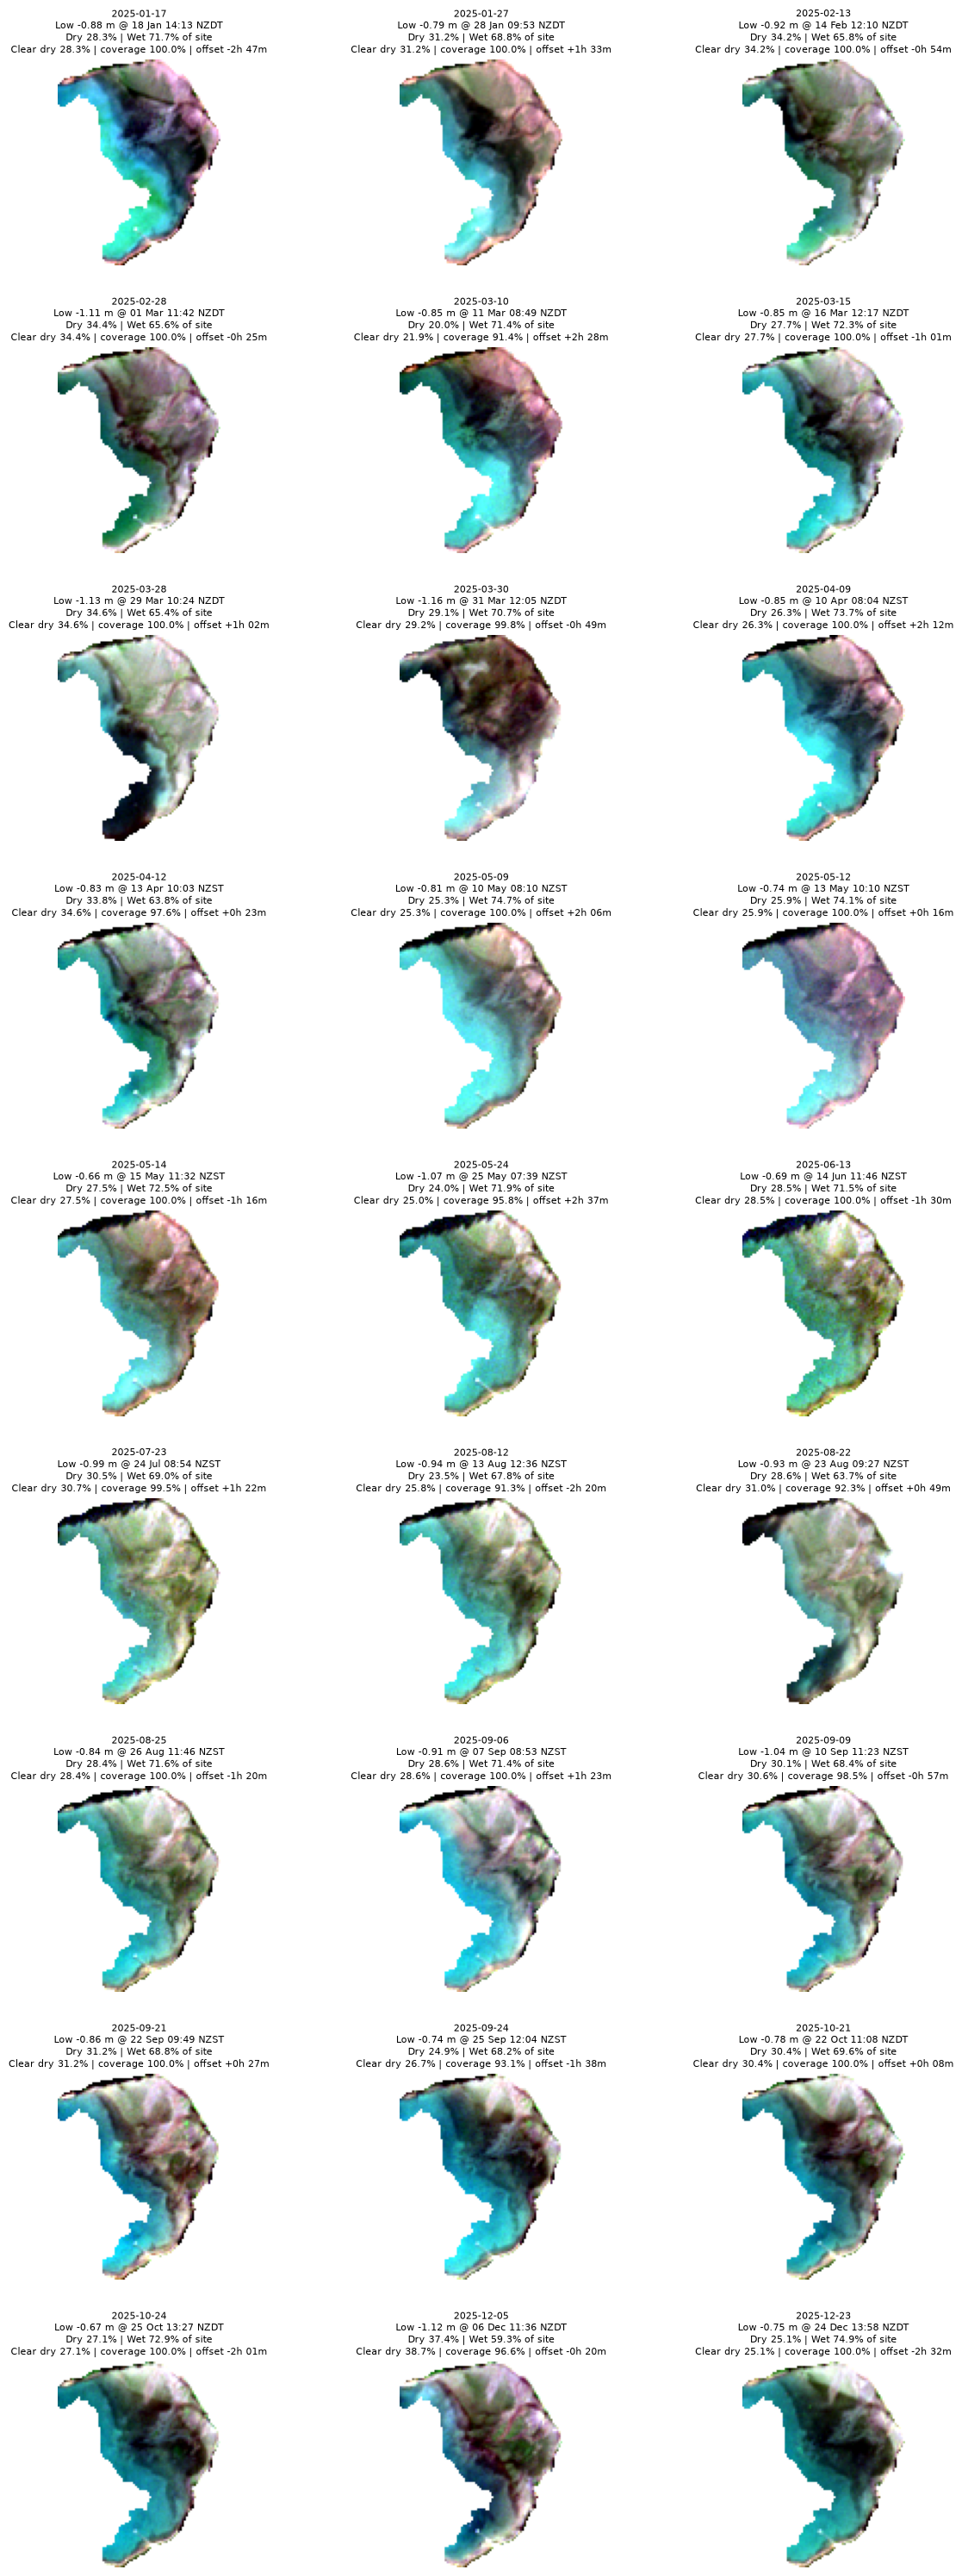

In [9]:
print("Lowest predicted local low-water levels among retained dates:")
display(results.sort_values("nearest_low_tide_height_msl").head(10)[[
    "date", "nearest_low_tide_height_msl", "tide_height_msl",
    "exposed_fraction_pct", "wet_fraction_pct", "exposed_fraction_of_clear_pct",
    "valid_pixel_fraction_pct", "hours_from_low_tide",
]])

ncols = 3
nrows = int(numpy.ceil(len(scene_dates) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.2 * nrows), squeeze=False)
for i, (ax, scene_date) in enumerate(zip(axes.flat, scene_dates)):
    rgb = numpy.stack(
        [satellite_data[band].isel(time=i).values for band in sentinel2.RGB_BANDS],
        axis=-1,
    ).astype(numpy.float32)
    display_valid = numpy.isfinite(rgb).all(axis=-1) & (rgb > 0).all(axis=-1)
    rgb_display = numpy.ones_like(rgb)
    if display_valid.any():
        for channel in range(3):
            pixels = rgb[..., channel][display_valid]
            low, high = numpy.percentile(pixels, [2, 98])
            if high > low:
                rgb_display[..., channel] = numpy.clip(
                    (rgb[..., channel] - low) / (high - low), 0, 1
                )
    rgb_display[~display_valid] = 1
    row = results.loc[results["date"] == scene_date].iloc[0]
    low_tide_local = pandas.Timestamp(row["nearest_low_tide_time_utc"]).tz_convert("Pacific/Auckland")
    offset_total_minutes = int(round(float(row["hours_from_low_tide"]) * 60))
    offset_sign = "+" if offset_total_minutes >= 0 else "-"
    offset_hours, offset_minutes = divmod(abs(offset_total_minutes), 60)
    offset_text = f"{offset_sign}{offset_hours}h {offset_minutes:02d}m"
    ax.imshow(rgb_display)
    ax.set_title(
        f"{scene_date}\nLow {row['nearest_low_tide_height_msl']:.2f} m @ "
        f"{low_tide_local:%d %b %H:%M %Z}\n"
        f"Dry {row['exposed_fraction_pct']:.1f}% | Wet {row['wet_fraction_pct']:.1f}% of site\n"
        f"Clear dry {row['exposed_fraction_of_clear_pct']:.1f}% | "
        f"coverage {row['valid_pixel_fraction_pct']:.1f}% | offset {offset_text}",
        fontsize=8,
        pad=6,
    )
    ax.axis("off")

for ax in axes.flat[len(scene_dates):]:
    ax.axis("off")
fig.subplots_adjust(hspace=0.4, wspace=0.08)
plt.show()

## Select a Reviewed Reference Date (Optional)

Use the ranked table and visual inspection to choose a low-exposure candidate as a reference. This is a comparison among satellite dates, not an estimate of the unknown UAV acquisition tide state.

In [10]:
if REFERENCE_DATE is not None:
    reference_rows = results[results["date"] == REFERENCE_DATE]
    if reference_rows.empty:
        raise ValueError(f"REFERENCE_DATE {REFERENCE_DATE} is not in the low-tide candidate results.")
    reference_row = reference_rows.iloc[0]
    print(f"Reference date: {REFERENCE_DATE}")
    print(f"Exposed/dry fraction of full site: {reference_row['exposed_fraction_pct']:.1f}%")
    print(f"Wet fraction of full site: {reference_row['wet_fraction_pct']:.1f}%")
    print(f"Exposed among clear pixels: {reference_row['exposed_fraction_of_clear_pct']:.1f}%")
    print(f"Valid pixel coverage: {reference_row['valid_pixel_fraction_pct']:.1f}%")
    print(f"Predicted tide at acquisition: {reference_row['tide_height_msl']:.2f} m MSL")
    print(f"Nearest low tide: {reference_row['nearest_low_tide_time_utc']}")
else:
    print("After reviewing results, optionally set REFERENCE_DATE and rerun the plotting cell.")

results["reference_date"] = REFERENCE_DATE

Reference date: 2025-12-05
Exposed/dry fraction of full site: 37.4%
Wet fraction of full site: 59.3%
Exposed among clear pixels: 38.7%
Valid pixel coverage: 96.6%
Predicted tide at acquisition: -1.12 m MSL
Nearest low tide: 2025-12-05 22:36:00+00:00


## Interactive Tide Height and Whole-Site Exposure

Hover over a point for acquisition time and tide height, nearest low-water time and height, signed offset, whole-site wet/dry percentages, clear-only percentages, SCL coverage, ignored-pixel percentage, and valid-pixel coverage. The optional reference date is marked with a star.

In [11]:
import plotly.express as px
from IPython.display import FileLink, display

plot_data = results.dropna(subset=["tide_height_msl", "exposed_fraction_pct"]).copy()
if plot_data.empty:
    raise ValueError("No valid tide/exposure estimates to plot.")

plot_data["nearest_low_tide_local"] = (
    pandas.to_datetime(plot_data["nearest_low_tide_time_utc"], utc=True)
    .dt.tz_convert("Pacific/Auckland")
    .dt.strftime("%Y-%m-%d %H:%M %Z")
)

def format_low_tide_offset(hours_from_low):
    total_minutes = int(round(float(hours_from_low) * 60))
    sign = "+" if total_minutes >= 0 else "-"
    hours, minutes = divmod(abs(total_minutes), 60)
    return f"{sign}{hours}h {minutes:02d}m"


plot_data["low_tide_offset"] = plot_data["hours_from_low_tide"].map(format_low_tide_offset)
plot_data["plot_role"] = numpy.where(
    plot_data["date"] == REFERENCE_DATE, "Reference", "Candidate"
)

fig = px.scatter(
    plot_data,
    x="tide_height_msl",
    y="exposed_fraction_pct",
    color="hours_from_low_tide",
    symbol="plot_role",
    symbol_map={"Candidate": "circle", "Reference": "star"},
    color_continuous_scale="RdBu_r",
    hover_name="date",
    hover_data={
        "satellite_time_utc": True,
        "tide_height_msl": ":.2f",
        "nearest_low_tide_local": True,
        "nearest_low_tide_height_msl": ":.2f",
        "low_tide_offset": True,
        "wet_fraction_pct": ":.1f",
        "exposed_fraction_pct": ":.1f",
        "wet_fraction_of_clear_pct": ":.1f",
        "exposed_fraction_of_clear_pct": ":.1f",
        "scl_coverage_pct": ":.1f",
        "scl_ignore_pct": ":.1f",
        "valid_pixel_fraction_pct": ":.1f",
        "hours_from_low_tide": False,
        "plot_role": False,
        "date": False,
    },
    labels={
        "tide_height_msl": "Predicted tide height at acquisition (m MSL)",
        "exposed_fraction_pct": "Exposed fraction of full site polygon (%)",
        "hours_from_low_tide": "Hours from nearest low tide",
    },
    title=f"Robinsons Bay: {YEAR} low-tide candidates (full site polygon)",
)
fig.update_traces(marker={"size": 11, "line": {"width": 0.8, "color": "white"}})
fig.update_layout(
    height=650,
    hovermode="closest",
    legend_title_text="",
    coloraxis_colorbar_title="Hours from low tide<br>(negative = before)",
    yaxis={"range": [0, 105]},
)

html_file = output_path / f"{SITE_NAME}_{YEAR}_tide_height_vs_exposure.html"
csv_file = output_path / f"{SITE_NAME}_{YEAR}_tide_exposure_dates.csv"
fig.write_html(html_file, include_plotlyjs=True, auto_open=False)
results.to_csv(csv_file, index=False)
display(FileLink(str(html_file)))

print(f"Saved interactive plot: {html_file}")
print(f"Saved measurements: {csv_file}")

C:\Local\repos\seagrass-detection\data\analysis\robinsons_tide_exposure\Robinsons_2025_tide_height_vs_exposure.html

Saved interactive plot: C:\Local\repos\seagrass-detection\data\analysis\robinsons_tide_exposure\Robinsons_2025_tide_height_vs_exposure.html
Saved measurements: C:\Local\repos\seagrass-detection\data\analysis\robinsons_tide_exposure\Robinsons_2025_tide_exposure_dates.csv


In [12]:
display(excluded_dates[
    ["date", "tide_height_msl", "hours_from_low_tide", "scl_ignore_pct"]
].sort_values("tide_height_msl"))

,date,tide_height_msl,hours_from_low_tide,scl_ignore_pct
21,2025-04-27,-1.16,0.630284,100.000000
27,2025-05-27,-1.10,0.063618,100.000000
22,2025-04-29,-1.09,-1.344160,100.000000
54,2025-10-09,-1.07,-1.616382,100.000000
53,2025-10-06,-1.06,0.989174,100.000000
59,2025-11-08,-1.06,-2.385826,100.000000
63,2025-12-03,-1.06,1.744173,36.785199
11,2025-03-03,-1.05,-2.830271,100.000000
6,2025-02-01,-1.04,-2.363604,100.000000
32,2025-06-23,-1.04,2.035840,100.000000
